# 3. Demand

Demand is what every solve must meet, bus by bus and hour by hour. This tutorial looks at the same February week in
three years, each built a different way:

| Year | Scenario | How demand is built |
|---|---|---|
| 2020 | `Tutorial_2020_reduced` ([tutorial 1](1-first-run-2020.ipynb)) | measured: ESPENI's GB demand for the week, shared out by bus |
| 2030 | `CP30_FFR_2030_tutorial_week` ([tutorial 5](5-two-stage-market-2030.ipynb)) | CP30's annual demand, built from its parts (heat pumps, electric vehicles, data centres) with their own hourly shapes, part of it flexible |
| 2040 | `Tutorial_2040_HT_clustered` ([tutorial 4](4-future-2040-holistic-transition.ipynb)) | FES's annual demand by GSP, given the hourly shape of the demand year |

This notebook reads those three runs; it solves nothing itself. Each is described in full in the model description
([demand](../model/demand/index.md), [consumer flexibility](../model/flexibility/consumer.md)).

In [1]:
from pathlib import Path
import logging
import os
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import pypsa

logging.getLogger("pypsa").setLevel(logging.ERROR)  # keep the notebook output short
warnings.filterwarnings("ignore", message=".*GDAL.*")
warnings.filterwarnings("ignore", message=".*gdalvrt.*")

# Work from the repository root, wherever Jupyter was started.
ROOT = Path.cwd()
while not (ROOT / "Snakefile").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)

# Technology groups for charts: each PyPSA-GB carrier belongs to one group.
GROUPS = {
    "Nuclear": ["nuclear"],
    "Coal": ["coal"],
    "Gas": ["CCGT", "OCGT", "gas_engine", "CHP", "CCS Gas"],
    "Oil": ["oil"],
    "Bioenergy": ["biomass", "CCS Biomass", "biogas", "landfill_gas", "sewage_gas", "waste_to_energy",
                  "advanced_biofuel", "geothermal"],
    "Hydro": ["large_hydro", "small_hydro"],
    "Marine": ["marine", "tidal_stream", "shoreline_wave", "tidal_lagoon"],
    "Onshore wind": ["wind_onshore", "embedded_wind"],
    "Offshore wind": ["wind_offshore", "floating_wind"],
    "Solar": ["solar_pv", "embedded_solar"],
}
GROUP_OF = {carrier: group for group, carriers in GROUPS.items() for carrier in carriers}
COLOURS = {
    "Nuclear": "#6250d6", "Coal": "#4b4b4b", "Gas": "#eb6834", "Oil": "#9b6a4f", "Bioenergy": "#008300",
    "Hydro": "#5fa8d3", "Marine": "#1f9e9e", "Onshore wind": "#1baf7a", "Offshore wind": "#2a78d6",
    "Solar": "#eda100", "Hydrogen": "#e34948", "Storage": "#e87ba4", "Imports": "#9aa5a0",
}
# Consumer flexibility (EVs, heat, demand response) is built from storage units but counts as demand.
CONSUMER_FLEX = {"EV_smart_charging", "V2G_fleet", "HP_flexibility", "DH_flexibility", "SH_flexibility",
                 "IC_DSR", "residential_DSR", "DACCS"}

plt.rcParams.update({"figure.figsize": (10, 4.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e9e7", "legend.frameon": False, "font.size": 10})


def load(path):
    """Open a solved network, or say how to make it."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"{path} does not exist yet: run the scenario first (see 'Run it' above).")
    return pypsa.Network(path)


def series(n, component, attribute, names):
    """A time series for each named component; a component without one takes its static value (or zero)."""
    table = getattr(n, f"{component}_t")[attribute]
    static = getattr(n, component).get(attribute, pd.Series(0.0, index=getattr(n, component).index))
    out = table.reindex(columns=names)
    for name in out.columns[out.isna().all()]:
        out[name] = float(static.get(name, 0.0)) if attribute in ("p_set", "p_max_pu") else 0.0
    return out.fillna(0.0)


def link_output(n, names):
    """Power each link delivers at its bus1 end (MW): p0 times efficiency, so it works whether or not p1 was saved."""
    return series(n, "links", "p0", names) * n.links.efficiency.reindex(names).values


def gb_buses(n):
    """GB electricity buses (the hydrogen bus is left out)."""
    return n.buses.index[(n.buses.country == "GB") & (n.buses.carrier == "AC")]


def generation_by_group(n):
    """GB generation by technology group (MW per snapshot); hydrogen turbines are their own group."""
    gens = n.generators[n.generators.bus.isin(gb_buses(n)) & n.generators.carrier.isin(GROUP_OF)]
    out = series(n, "generators", "p", gens.index).T.groupby(gens.carrier.map(GROUP_OF)).sum().T
    turbines = n.links.index[n.links.carrier == "H2_turbine"]
    if len(turbines):
        out["Hydrogen"] = link_output(n, turbines).sum(axis=1)  # output at the electricity end
    return out[[g for g in COLOURS if g in out and out[g].abs().sum() > 0]]


def interconnectors(n):
    cc = n.links.get("counterparty_country", pd.Series("", index=n.links.index)).fillna("").astype(str)
    return n.links[(n.links.carrier == "DC") & ~cc.isin(["", "nan", "None"])]


def net_imports(n):
    """Power the interconnectors deliver into GB (MW; negative = export)."""
    ic = interconnectors(n)
    gb = set(gb_buses(n))
    flows = {}
    for name, link in ic.iterrows():
        # p0 and p1 are withdrawals at bus0 and bus1; the GB end receives minus its withdrawal.
        # Power into GB: at bus0 it is minus the flow out of bus0; at bus1 it is the link's output there.
        flows[name] = (-series(n, "links", "p0", [name])[name] if link.bus0 in gb
                       else link_output(n, [name])[name])
    return pd.DataFrame(flows, index=n.snapshots).sum(axis=1)


def grid_storage(n):
    """Net output of grid storage (MW; positive = discharging). Consumer flexibility is left out."""
    units = n.storage_units.index[~n.storage_units.carrier.isin(CONSUMER_FLEX)]
    return series(n, "storage_units", "p", units).sum(axis=1)


def gb_demand(n):
    """GB electricity demand (MW): loads, the net draw of consumer flexibility, and electrolysis."""
    loads = n.loads.index[n.loads.bus.isin(gb_buses(n))]
    demand = series(n, "loads", "p_set", loads).sum(axis=1)
    flex = n.storage_units.index[n.storage_units.carrier.isin(CONSUMER_FLEX)]
    if len(flex):
        demand = demand - series(n, "storage_units", "p", flex).sum(axis=1)
    electrolysers = n.links.index[n.links.carrier == "electrolysis"]
    if len(electrolysers):
        demand = demand + series(n, "links", "p0", electrolysers).sum(axis=1)
    return demand


def day_axis(ax):
    """Label a time axis by day: Mon 10 Feb."""
    import matplotlib.dates as mdates
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))


def stack_plot(ax, supply, demand=None, title=None):
    """Stacked supply (GW) by group, positive above zero and negative (charging, exports) below."""
    gw = supply / 1e3
    pos, neg = gw.clip(lower=0), gw.clip(upper=0)
    ax.stackplot(gw.index, pos.T.values, colors=[COLOURS[c] for c in gw.columns], labels=gw.columns, lw=0)
    ax.stackplot(gw.index, neg.T.values, colors=[COLOURS[c] for c in gw.columns], lw=0)
    if demand is not None:
        ax.plot(demand.index, demand / 1e3, color="black", lw=1.4, label="Demand")
    ax.axhline(0, color="#555", lw=0.6)
    ax.set_ylabel("GW")
    day_axis(ax)
    if title:
        ax.set_title(title, loc="left")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))


import geopandas as gpd
from matplotlib.collections import LineCollection

GB_OUTLINE = gpd.read_file("data/network/GSP/GSP_regions_27700_20250109.geojson").to_crs(27700).dissolve()


def network_map(ax, n, line_values=None, cmap="viridis", vmin=0, vmax=1, bus_size=6, title=None):
    """GB buses and AC lines on British National Grid coordinates (metres); lines coloured by line_values."""
    GB_OUTLINE.plot(ax=ax, color="#eef3f0", edgecolor="#c9d6cf", lw=0.4)
    buses = n.buses.loc[gb_buses(n)]
    lines = n.lines[n.lines.bus0.isin(buses.index) & n.lines.bus1.isin(buses.index)]
    segments = [[(buses.x[a], buses.y[a]), (buses.x[b], buses.y[b])] for a, b in zip(lines.bus0, lines.bus1)]
    internal = n.links[n.links.carrier.isin(["DC", "AC"]) & n.links.bus0.isin(buses.index)
                       & n.links.bus1.isin(buses.index)]
    ax.add_collection(LineCollection(
        [[(buses.x[a], buses.y[a]), (buses.x[b], buses.y[b])] for a, b in zip(internal.bus0, internal.bus1)],
        colors="#7a8f86", linewidths=0.9, linestyles="dashed"))  # links inside GB (HVDC; zonal transport links)
    if line_values is None:
        collection = LineCollection(segments, colors="#7a8f86", linewidths=0.8)
    else:
        collection = LineCollection(segments, array=line_values.reindex(lines.index).values, cmap=cmap,
                                    linewidths=1.6, norm=plt.Normalize(vmin, vmax))
    ax.add_collection(collection)
    ax.scatter(buses.x, buses.y, s=bus_size, color="#2f4f43", zorder=3)
    ax.set_xlim(-20_000, 680_000)
    ax.set_ylim(-10_000, 1_225_000)
    ax.set_aspect("equal")
    ax.set_axis_off()
    if title:
        ax.set_title(title, loc="left")
    return collection


RUNS = {
    "2020": "resources/network/Tutorial_2020_reduced_solved.nc",
    "2030": "resources/market/CP30_FFR_2030_tutorial_week_wholesale.nc",
    "2040": "resources/network/Tutorial_2040_HT_clustered_solved.nc",
}
networks = {}
for year, path in RUNS.items():
    if Path(path).exists():
        networks[year] = pypsa.Network(path)
    else:
        print(f"{year}: {path} not found; run its tutorial first")
print("Loaded:", ", ".join(networks))

Loaded: 2020, 2030, 2040


## Demand in PyPSA

A `Load` is fixed demand at a bus: its time series, in MW, is in `n.loads_t.p_set`, one column per load. Each GB bus
with demand has one. Loads outside GB stand for exports, and a load on the hydrogen bus is hydrogen demand outside the
power sector; neither is GB electricity demand.

In [2]:
n = networks["2020"]
gb_loads = n.loads[n.loads.bus.isin(gb_buses(n))]
print(f"{len(gb_loads)} GB loads; the five largest over the week (GWh):")
(series(n, "loads", "p_set", gb_loads.index).sum().sort_values(ascending=False).head(5) / 1e3).round(1)

29 GB loads; the five largest over the week (GWh):


name
load_London          969.9
load_Melksham        557.3
load_S.W.Penisula    522.4
load_Daines          502.1
load_Feckenham       454.5
dtype: float64

## The week in three years

The three weeks start on different weekdays (10 February was a Monday in 2020, a Sunday in 2030 and a Friday in 2040),
so the chart puts each on the hours since the start of its week.

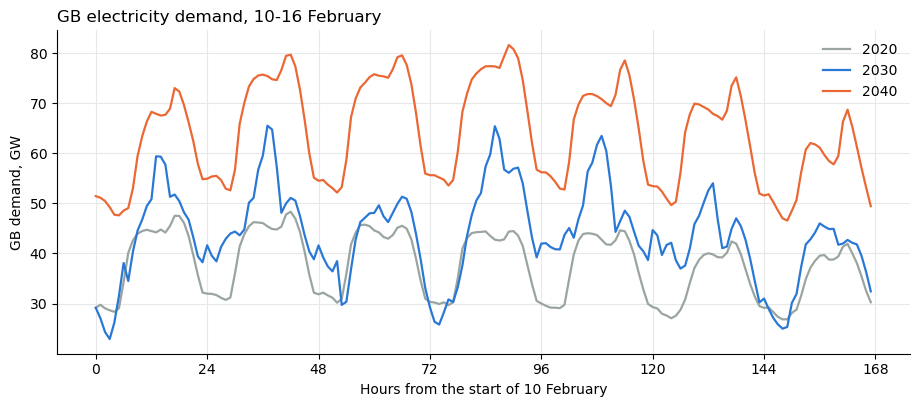

,2020,2030,2040
"energy, TWh",6.35,7.35,10.73
"peak, GW",48.34,65.50,81.59
"lowest, GW",26.86,22.94,46.57


In [3]:
fig, ax = plt.subplots(figsize=(11, 4.2))
colours = {"2020": "#9aa5a0", "2030": "#2a78d6", "2040": "#eb6834"}
rows = {}
for year, n in networks.items():
    demand = gb_demand(n) / 1e3
    ax.plot(range(len(demand)), demand.values, color=colours[year], lw=1.6, label=year)
    rows[year] = {"energy, TWh": demand.sum() / 1e3, "peak, GW": demand.max(), "lowest, GW": demand.min()}
ax.set_xlabel("Hours from the start of 10 February")
ax.set_ylabel("GB demand, GW")
ax.set_xticks(range(0, 169, 24))
ax.legend()
ax.set_title("GB electricity demand, 10-16 February", loc="left")
plt.show()
pd.DataFrame(rows).round(2)

Over this week demand grows by two-thirds from 2020 to 2040 (6.4 to 10.7 TWh) and the highest hour from 48 to 82
GW, as heating and transport move to electricity. The shapes differ as well. The 2020 week is measured and smooth. The
2030 week is built from its parts, and its flexible part is placed by the market, so its peaks are sharper and its
troughs deeper: flexible consumption moves into the cheapest hours. The 2040 week here takes one national shape,
scaled up, so it keeps the daily pattern of its demand year at a higher level; the
[FES long-range study](../studies/fes_long_range.md) builds 2040 from its parts as 2030 is built.

## Flexible demand in 2030

In the 2030 build, part of the demand of electric vehicles, heat pumps, heat networks and storage heaters, and some
demand response, can move in time. Each is a storage unit at the bus of the demand it shifts: it must consume the same
energy over the week, but the market chooses when. The chart splits 2030 demand into the fixed part and what each kind
of flexibility drew, with the wholesale price below.

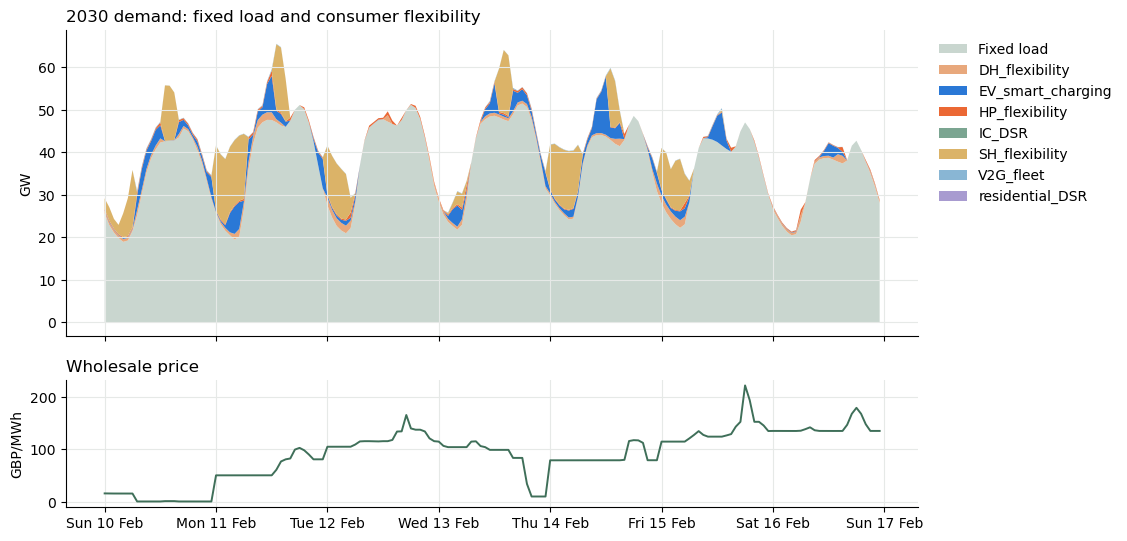

,"Power, GW"
carrier,
DH_flexibility,1.8
EV_smart_charging,37.9
HP_flexibility,1.2
IC_DSR,1.9
SH_flexibility,15.3
V2G_fleet,1.7
residential_DSR,2.6


In [4]:
if "2030" in networks:
    n = networks["2030"]
    fixed = series(n, "loads", "p_set", n.loads.index[n.loads.bus.isin(gb_buses(n))]).sum(axis=1)
    flex = n.storage_units[n.storage_units.carrier.isin(CONSUMER_FLEX)]
    draw = (-series(n, "storage_units", "p", flex.index)).T.groupby(flex.carrier).sum().T   # charging minus discharging
    price = pd.read_csv("resources/market/CP30_FFR_2030_tutorial_week_wholesale_price.csv", index_col=0,
                        parse_dates=True).wholesale_price

    flex_colours = {"EV_smart_charging": "#2a78d6", "V2G_fleet": "#89b6d4", "HP_flexibility": "#eb6834",
                    "DH_flexibility": "#e8a87c", "SH_flexibility": "#dbb368", "IC_DSR": "#7ba591",
                    "residential_DSR": "#a89bd0"}
    parts = pd.concat([fixed.rename("Fixed load"), draw], axis=1) / 1e3
    fig, (ax, axp) = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True, height_ratios=[2.4, 1])
    pos = parts.clip(lower=0)
    ax.stackplot(parts.index, pos.T.values, labels=parts.columns, lw=0,
                 colors=["#c9d6cf"] + [flex_colours.get(c, "#999") for c in draw.columns])
    ax.stackplot(parts.index, parts.clip(upper=0).T.values, lw=0,
                 colors=["#c9d6cf"] + [flex_colours.get(c, "#999") for c in draw.columns])
    ax.set_ylabel("GW")
    ax.set_title("2030 demand: fixed load and consumer flexibility", loc="left")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
    axp.plot(price.index, price, color="#3f6f59", lw=1.4)
    axp.set_ylabel("GBP/MWh")
    axp.set_title("Wholesale price", loc="left")
    day_axis(axp)
    plt.show()
    display((flex.groupby("carrier").p_nom.sum() / 1e3).round(1).to_frame("Power, GW"))

Storage heaters and smart-charged electric vehicles do most of the moving. They consume in the cheapest hours (on
Sunday 10 February, when wind takes the price to zero, and overnight) and almost nothing when the price is high, on 15
and 16 February. Smart charging has 38 GW of charging power and storage heaters 15 GW. Because every unit responds to
the same national price, the flexible demand also makes sharp peaks of its own when the price falls.

## Where demand is

Each bus's demand over the week, on the network it is placed on: the 32-bus network in 2020, the full network in
2030 (each GSP's demand at its own node) and the clustered network in 2040.

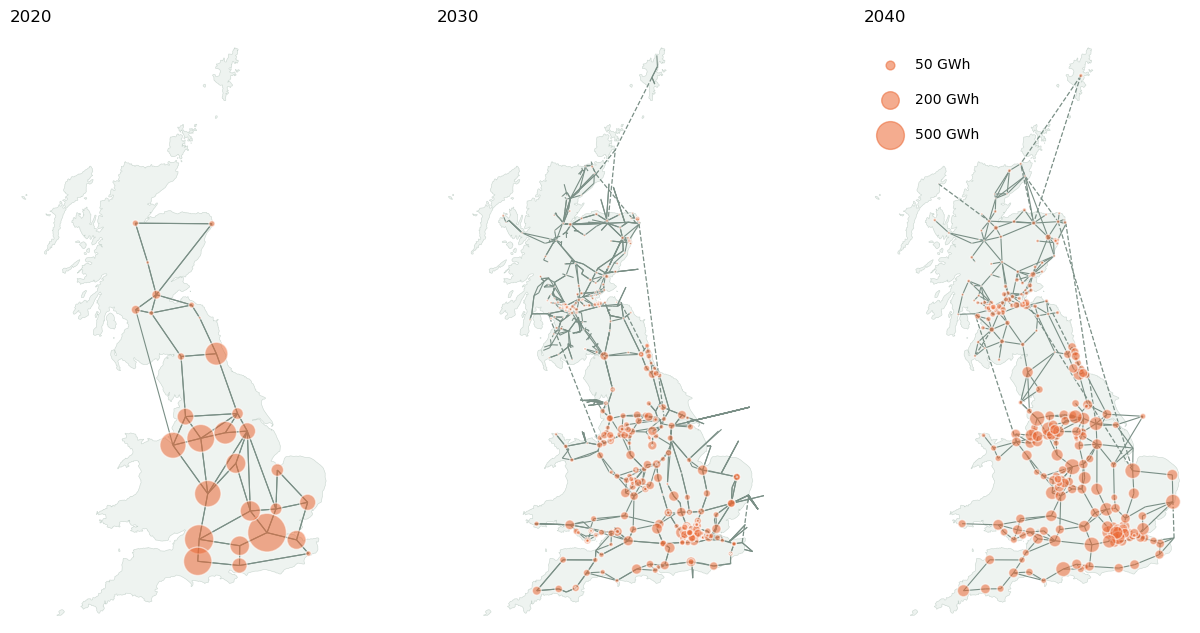

In [5]:
fig, axes = plt.subplots(1, len(networks), figsize=(5.2 * len(networks), 7.5))
axes = list(axes) if len(networks) > 1 else [axes]
for ax, (year, n) in zip(axes, networks.items()):
    loads = n.loads[n.loads.bus.isin(gb_buses(n))]
    by_bus = series(n, "loads", "p_set", loads.index).sum().groupby(loads.bus).sum() / 1e3    # GWh over the week
    buses = n.buses.loc[by_bus.index]
    network_map(ax, n, bus_size=0, title=year)
    ax.scatter(buses.x, buses.y, s=by_bus.clip(lower=0) * 0.8, color="#eb6834", alpha=0.55, edgecolor="white",
               zorder=4)
for size in (50, 200, 500):
    axes[-1].scatter([], [], s=size * 0.8, color="#eb6834", alpha=0.55, label=f"{size} GWh")
axes[-1].legend(loc="upper left", labelspacing=1.5)
plt.show()

Demand sits where people live: London and the South East, the Midlands and the North West. In 2030, on the full
network, each Grid Supply Point's demand is at its own node; in 2040, on the clustered network, at its region's bus.

## Try it yourself

**Another demand shape.** `demand_year` picks the year of ESPENI's hourly shape. Rerun tutorial 4's scenario with
`demand_year: 2019` and compare the 2040 week.

**A modelled demand profile.** Future scenarios can take their hourly shape from the eLOAD or DESSTINEE models
instead of ESPENI:

```yaml
My_2040_eload:
  inherits: Tutorial_2040_HT_clustered
  description: the 2040 tutorial week with the eLOAD 2050 demand profile
  demand:
    timeseries: eload
```